# Семинар 8: Введение в байесовскую статистику

## 0. Подготовка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit, logsumexp
from scipy.stats import beta, norm

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})
print("NumPy:", np.__version__)

NumPy: 2.3.5


## 1. Зачем нужна байесовская статистика?

Представим, что мы оцениваем вероятность того, что пользователь нажмёт на кнопку. После 10 показов получили 7 кликов. Частотный взгляд естественно спрашивает: *какая процедура оценки хорошо работает при многократном повторении эксперимента?* Байесовский взгляд задаёт другой вопрос: *какие значения неизвестной вероятности правдоподобны после увиденных данных?*

В байесовской статистике неизвестный параметр рассматривается как случайная величина. До данных у нас есть **априорное распределение** (*prior*) — описание того, какие значения параметра мы считали правдоподобными. Данные входят через **функцию правдоподобия** (*likelihood*). После обновления получаем **апостериорное распределение** (*posterior*).

Это полезно, когда:
- нужно явно учитывать уже имеющиеся знания или регуляризацию;
- важна неопределённость, а не только одна точечная оценка;
- данных мало или они приходят постепенно;
- требуется сравнивать модели (здесь появляется evidence).

Байесовский подход не «отменяет» частотный: это разные постановки вопроса. 
Однако, частотный подход является частным случаем байесовского. Об этом мы говорили на лекции
Prior — не бесплатная информация и не способ гарантированно улучшить результат; его влияние нужно проверять

### Формула Байеса: что именно обновляется?

Для параметра $\theta$ и данных $D$:

$$
p(\theta\mid D)=\frac{p(D\mid\theta)p(\theta)}{p(D)}.
$$

- $p(\theta)$ — prior;
- $p(D\mid\theta)$ — likelihood: насколько данные согласуются с параметром;
- $p(\theta\mid D)$ — posterior;
- $p(D)$ — evidence, нормирующая константа.

Важно: likelihood рассматривается как функция параметра при фиксированных данных. Это не обязательно распределение по параметру.

## 2. Из чего складывается модель: prior и likelihood

Простой пример — число успехов $k$ в $n$ независимых испытаниях Бернулли:
$$
k\mid\theta \sim \operatorname{Binomial}(n,\theta),\qquad
p(k\mid\theta)={n\choose k}\theta^k(1-\theta)^{n-k}.
$$

Параметр $\theta$ — неизвестная вероятность успеха. Выберем prior $\theta\sim\operatorname{Beta}(\alpha,\beta)$.

/tmp/ipykernel_339/733814904.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ax.plot(theta, prior / np.trapz(prior, theta), label="Prior: Beta(2, 2)")
/tmp/ipykernel_339/733814904.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ax.plot(theta, likelihood / np.trapz(likelihood, theta), label="Likelihood (нормирована для графика)")


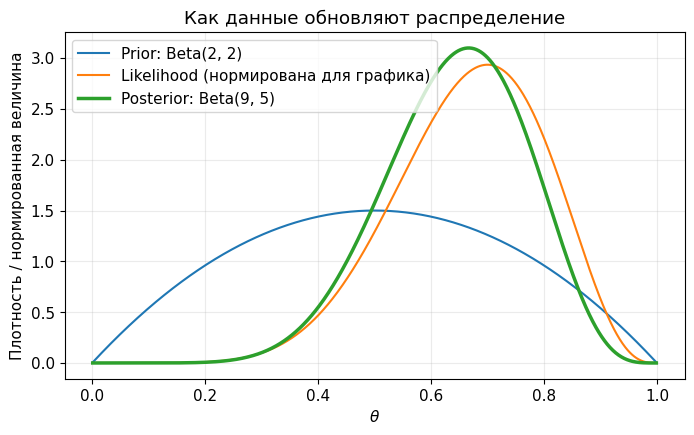

In [2]:
n, k = 10, 7
theta = np.linspace(0.001, 0.999, 1000)

# Likelihood как функция theta (комбинаторный множитель не влияет на форму)
likelihood = theta**k * (1-theta)**(n-k)
prior = beta.pdf(theta, 2, 2)
posterior = beta.pdf(theta, 2+k, 2+n-k)

fig, ax = plt.subplots()
ax.plot(theta, prior / np.trapz(prior, theta), label="Prior: Beta(2, 2)")
ax.plot(theta, likelihood / np.trapz(likelihood, theta), label="Likelihood (нормирована для графика)")
ax.plot(theta, posterior, label="Posterior: Beta(9, 5)", lw=2.5)
ax.set(xlabel=r"$\theta$", ylabel="Плотность / нормированная величина",
       title="Как данные обновляют распределение")
ax.legend()
plt.show()

**Как читать график.** Prior задаёт исходную форму. Likelihood выделяет значения параметра, при которых наблюдённые данные вероятны. Posterior сочетает оба источника информации и снова является корректной плотностью.

Likelihood на графике искусственно нормирована по $\theta$, только чтобы сравнить формы. В общем случае likelihood сама по себе не является плотностью вероятности параметра.

## 3. Evidence: интеграл, который может выглядеть пугающе

Evidence — вероятность данных, усреднённая по prior:
$$
p(D)=\int p(D\mid\theta)\,p(\theta)\,d\theta.
$$

Если $\theta$ — миллионы весов нейросети, интеграл становится многомерным:
$$
\boxed{
p(D\mid M)=
\int_{\mathbb R^{d}}
\underbrace{p(D\mid\mathbf w,M)}_{\text{likelihood нейросети}}
\underbrace{p(\mathbf w\mid M)}_{\text{prior на веса}}
\,d\mathbf w
}
$$

Это и есть evidence модели $M$. Здесь likelihood может быть получен обычным прямым проходом нейросети, а затем вычислением вероятности наблюдённых меток.

### Мини-нейросеть как likelihood

Сделаем крошечную сеть: один вход, два скрытых нейрона с `tanh`, sigmoid на выходе. Её веса $\mathbf w$ — параметры $\theta$. Для каждого набора весов сеть выдаёт вероятности клика, а likelihood — произведение вероятностей наблюдённых меток.

Мы не будем пытаться точно интегрировать по весам. Покажем принцип Монте-Карло: если $\mathbf w_s\sim p(\mathbf w)$, то
$$
p(D\mid M)=\mathbb E_{\mathbf w\sim p(\mathbf w)}[p(D\mid\mathbf w,M)]
\approx \frac1S\sum_{s=1}^S p(D\mid\mathbf w_s,M).
$$
В реальных нейросетях наивная оценка может иметь огромную дисперсию: почти все prior-сэмплы дают практически нулевой likelihood.

Отмечу также, что здесь очень простая сетка и Монте-Карло в целом применим. В общем случае мы упираемся в проклятье размерности

In [ ]:
# Игрушечные бинарные данные
x = np.array([-1.0, -0.6, -0.2, 0.2, 0.6, 1.0])
y = np.array([0, 0, 0, 1, 1, 1])

def nn_probability(x, w):
    # w = [W1(2), b1(2), W2(2), b2] — всего 7 параметров
    W1 = w[0:2]
    b1 = w[2:4]
    W2 = w[4:6]
    b2 = w[6]
    h = np.tanh(x[:, None] * W1[None, :] + b1[None, :])
    return expit(h @ W2 + b2)

def nn_log_likelihood(w):
    p = np.clip(nn_probability(x, w), 1e-12, 1-1e-12)
    return np.sum(y*np.log(p) + (1-y)*np.log1p(-p))

# Независимый нормальный prior на веса
prior_sd = 1.0
S = 20_000
W = rng.normal(0, prior_sd, size=(S, 7))
log_liks = np.array([nn_log_likelihood(w) for w in W])

# log(mean(exp(log_liks))) вычисляем устойчиво к переполнению/underflow
log_evidence_mc = logsumexp(log_liks) - np.log(S)
print(f"Оценка log evidence по prior Monte Carlo: {log_evidence_mc:.3f}")
print("Доля сэмплов с log-likelihood < -20:", np.mean(log_liks < -20))

Оценка log evidence по prior Monte Carlo: -4.178
Доля сэмплов с log-likelihood < -20: 0.0001


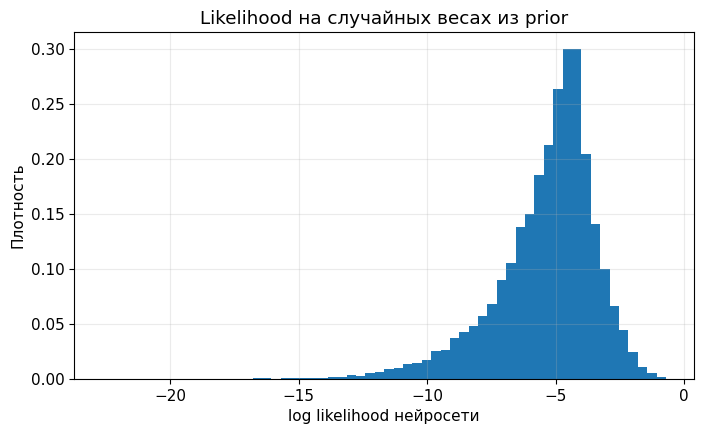

In [4]:
fig, ax = plt.subplots()
ax.hist(log_liks, bins=60, density=True)
ax.set(xlabel="log likelihood нейросети", ylabel="Плотность",
       title="Likelihood на случайных весах из prior")
plt.show()

**Почему интеграл страшный?** Размерность равна числу параметров; масса интеграла может находиться в очень узкой области пространства весов; likelihood часто почти нулевой для случайных весов. Поэтому наивный Monte Carlo может быть неэффективен. В прикладных задачах используют специальные методы приближения evidence (например, nested sampling, bridge sampling, методы на основе аппроксимаций), а иногда сравнивают модели через предсказательную проверку, не вычисляя evidence напрямую.

## 4. Сопряжённые распределения: пример Beta–Binomial

Сопряжённость означает, что после обновления posterior принадлежит тому же семейству распределений, что и prior. Для биномиальной модели и Beta-prior:
$$
\theta\sim\operatorname{Beta}(\alpha,\beta),\quad
k\mid\theta\sim\operatorname{Binomial}(n,\theta)
$$
получаем
$$
\boxed{\theta\mid k,n\sim
\operatorname{Beta}(\alpha+k,\ \beta+n-k).}
$$

То есть обновление сводится к прибавлению числа успехов и неудач к параметрам prior. Это не магия, а результат перемножения плотности prior и likelihood.

Posterior: Beta(9, 5)
Аналитическое среднее: 0.6428571428571429
Формула через prior + данные: 0.6428571428571429


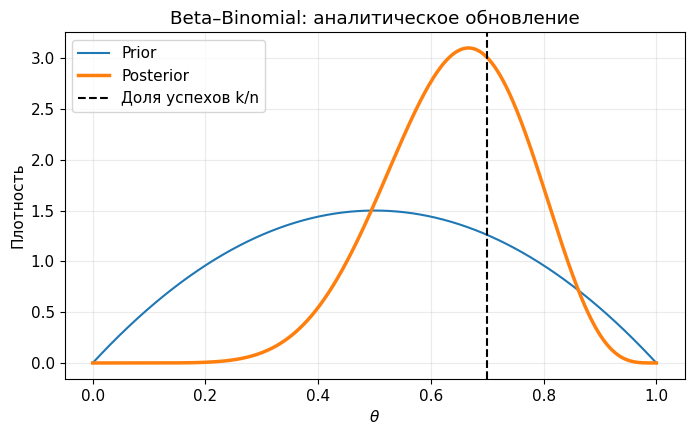

In [5]:
alpha, beta_prior = 2, 2
n, k = 10, 7
a_post = alpha + k
b_post = beta_prior + n - k

print(f"Posterior: Beta({a_post}, {b_post})")
print("Аналитическое среднее:", a_post / (a_post + b_post))
print("Формула через prior + данные:",
      (alpha + k) / (alpha + beta_prior + n))

grid = np.linspace(0, 1, 1000)
fig, ax = plt.subplots()
ax.plot(grid, beta.pdf(grid, alpha, beta_prior), label="Prior")
ax.plot(grid, beta.pdf(grid, a_post, b_post), label="Posterior", lw=2.5)
ax.axvline(k/n, color="black", ls="--", label="Доля успехов k/n")
ax.set(xlabel=r"$\theta$", ylabel="Плотность", title="Beta–Binomial: аналитическое обновление")
ax.legend()
plt.show()

### Evidence здесь тоже считается аналитически

Для Beta–Binomial:
$$
p(k\mid n,\alpha,\beta)
={n\choose k}\frac{B(\alpha+k,\beta+n-k)}{B(\alpha,\beta)}.
$$
Это интеграл likelihood по prior, но сопряжённость позволяет вычислить его через бета-функцию. Ниже используем `scipy.special.betaln`, чтобы считать в логарифмах.

In [6]:
from scipy.special import betaln, gammaln

log_evidence = (
    gammaln(n+1) - gammaln(k+1) - gammaln(n-k+1)
    + betaln(alpha+k, beta_prior+n-k)
    - betaln(alpha, beta_prior)
)
print("log evidence =", log_evidence)
print("evidence =", np.exp(log_evidence))

log evidence = -2.190255908020125
evidence = 0.11188811188811201


## 5. Prior имеет значение — особенно когда данных мало

Prior не обязан быть «объективным» или единственно правильным. Он должен выражать разумные допущения о параметре до наблюдения данных. Сравним три prior для одной и той же выборки: равномерный Beta(1,1), более концентрированный около 0.5 Beta(20,20) и prior, смещённый к большим значениям Beta(8,2).

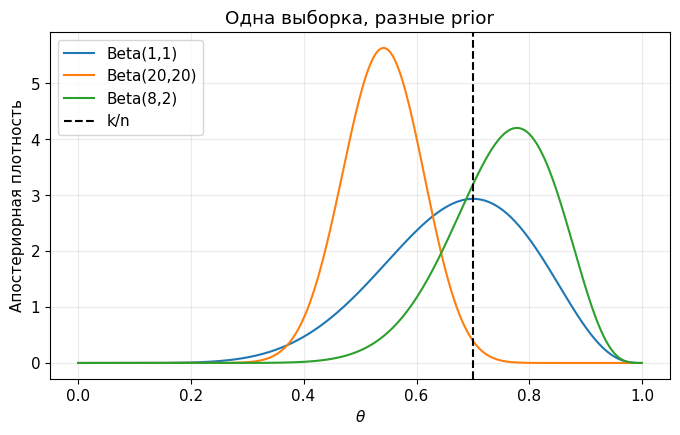

In [7]:
priors = [(1, 1, "Beta(1,1)"), (20, 20, "Beta(20,20)"), (8, 2, "Beta(8,2)")]
grid = np.linspace(0.001, 0.999, 1000)
fig, ax = plt.subplots()
for a, b, label in priors:
    ax.plot(grid, beta.pdf(grid, a+k, b+n-k), label=label)
ax.axvline(k/n, color="black", ls="--", label="k/n")
ax.set(xlabel=r"$\theta$", ylabel="Апостериорная плотность",
       title="Одна выборка, разные prior")
ax.legend()
plt.show()

При малом $n$ prior может заметно сдвинуть и сузить posterior. Это не недостаток вычислений — это следствие того, что исходные предположения всё ещё вносят существенный вклад.

Практическая привычка: проводить **анализ чувствительности** — повторять выводы с несколькими разумными prior и смотреть, меняются ли содержательные выводы. Сильный prior требует особенно ясного обоснования.

## 6. Статистики posterior и интервалы

Posterior — целое распределение, а не одна оценка. Из него можно извлечь:
- **среднее** — оптимально при квадратичной функции потерь;
- **медиану** — оптимальна при абсолютной функции потерь;
- **моду** — точку максимальной плотности (MAP; зависит от параметризации и может быть неустойчивой);
- **квантили и интервалы** — диапазон правдоподобных значений параметра.

Например, 95%-й равновероятностный (equal-tailed) credible interval содержит по 2.5% posterior-массы в каждом хвосте. Это не то же самое, что частотный 95%-й доверительный интервал: байесовская интерпретация относится к вероятности параметра при данных и модели.

In [8]:
post = beta(a_post, b_post)
mean_post = post.mean()
median_post = post.median()
mode_post = (a_post-1)/(a_post+b_post-2) if a_post > 1 and b_post > 1 else np.nan
ci_equal = post.ppf([0.025, 0.975])

# Простой HDI для одномерного распределения: кратчайшее окно,
# содержащее заданную долю эмпирических сэмплов.
samples = post.rvs(size=200_000, random_state=rng)
def hdi_1d(draws, mass=0.95):
    s = np.sort(np.asarray(draws))
    m = int(np.floor(mass * len(s)))
    widths = s[m:] - s[:len(s)-m]
    i = np.argmin(widths)
    return s[i], s[i+m]

ci_hdi = hdi_1d(samples)
print(f"Среднее posterior: {mean_post:.3f}")
print(f"Медиана posterior: {median_post:.3f}")
print(f"Мода / MAP: {mode_post:.3f}")
print(f"95% equal-tailed: [{ci_equal[0]:.3f}, {ci_equal[1]:.3f}]")
print(f"95% HDI (по сэмплам): [{ci_hdi[0]:.3f}, {ci_hdi[1]:.3f}]")

Среднее posterior: 0.643
Медиана posterior: 0.650
Мода / MAP: 0.667
95% equal-tailed: [0.386, 0.861]
95% HDI (по сэмплам): [0.400, 0.872]


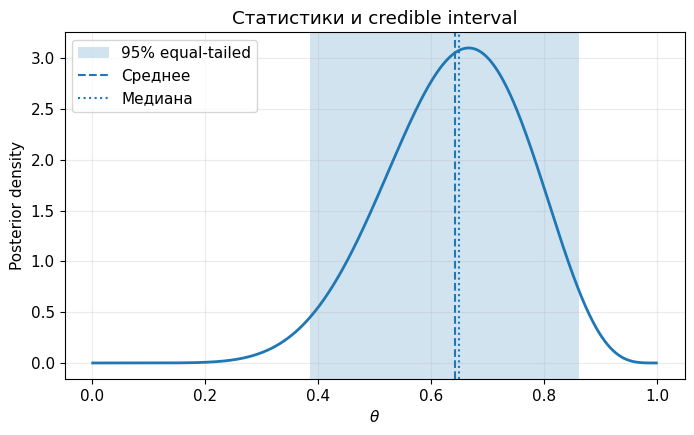

In [9]:
fig, ax = plt.subplots()
ax.plot(grid, post.pdf(grid), lw=2)
ax.axvspan(*ci_equal, alpha=0.2, label="95% equal-tailed")
ax.axvline(mean_post, ls="--", label="Среднее")
ax.axvline(median_post, ls=":", label="Медиана")
ax.set(xlabel=r"$\theta$", ylabel="Posterior density",
       title="Статистики и credible interval")
ax.legend()
plt.show()

**Интерпретация:** при заданной модели и prior posterior-масса между границами 95%-го credible interval равна 0.95. Это утверждение о параметре после наблюдения данных. Оно не означает, что 95% новых наблюдений попадут в этот интервал: для предсказаний строят posterior predictive distribution.

HDI — интервал с наибольшей плотностью (в одномерном случае кратчайший интервал заданной массы, если плотность достаточно регулярна). Для асимметричных распределений он может отличаться от equal-tailed. В многомодальных распределениях HDI может быть объединением нескольких отрезков; наша функция выше возвращает только один отрезок и потому не подходит для такого случая.

## 7. MCMC: как получить сэмплы, если posterior сложно посчитать?

В сложных моделях мы знаем posterior с точностью до нормирующей константы:
$$
p(\theta\mid D)\propto p(D\mid\theta)p(\theta),
$$
но не умеем эффективно вычислять интегралы, средние или квантили. **MCMC** (Markov chain Monte Carlo) строит зависимую последовательность состояний, чьё стационарное распределение — нужный posterior. После прогрева и при хорошей сходимости сэмплы позволяют приближать характеристики posterior.

Ключевая мысль: MCMC не «угадывает» posterior по гистограмме; алгоритм строит цепь с математически заданным целевым распределением. Но конечная цепь может плохо перемещаться, застревать или не исследовать все области.

### 7.1 Metropolis–Hastings на двумодальном распределении

Выберем целевую плотность — смесь двух нормальных распределений. Она специально сделана двумодальной, чтобы было видно, насколько важно перемещение цепи между модами.

На каждом шаге:
1. предлагаем новое значение из proposal $q(\theta'\mid\theta)$;
2. принимаем его с вероятностью
$$
a=\min\left(1,\frac{\pi(\theta')q(\theta\mid\theta')}
{\pi(\theta)q(\theta'\mid\theta)}\right);
$$
3. если предложение отклонено, остаёмся на старом значении.

Для симметричного случайного шага $q(\theta'\mid\theta)=q(\theta\mid\theta')$, и отношение proposal сокращается.

In [10]:
def log_target(z):
    # Смесь N(-3, 0.7^2) и N(3, 0.7^2) с равными весами
    a = np.log(0.5) + norm.logpdf(z, loc=-3, scale=0.7)
    b = np.log(0.5) + norm.logpdf(z, loc= 3, scale=0.7)
    return np.logaddexp(a, b)

def metropolis_hastings(n_steps=30_000, proposal_sd=1.0, start=0.0, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    chain = np.empty(n_steps)
    current = float(start)
    current_lp = log_target(current)
    accepted = 0
    for t in range(n_steps):
        proposal = current + rng.normal(0, proposal_sd)
        proposal_lp = log_target(proposal)
        if np.log(rng.uniform()) < proposal_lp - current_lp:
            current, current_lp = proposal, proposal_lp
            accepted += 1
        chain[t] = current
    return chain, accepted/n_steps

mh_chain, mh_accept = metropolis_hastings(rng=rng)
print("Acceptance rate:", round(mh_accept, 3))

Acceptance rate: 0.604


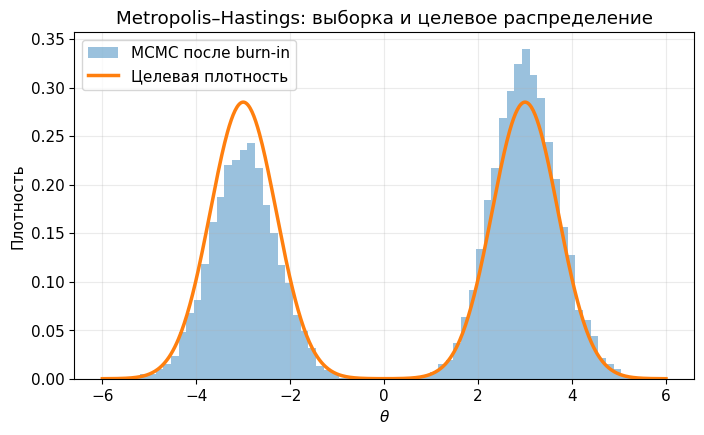

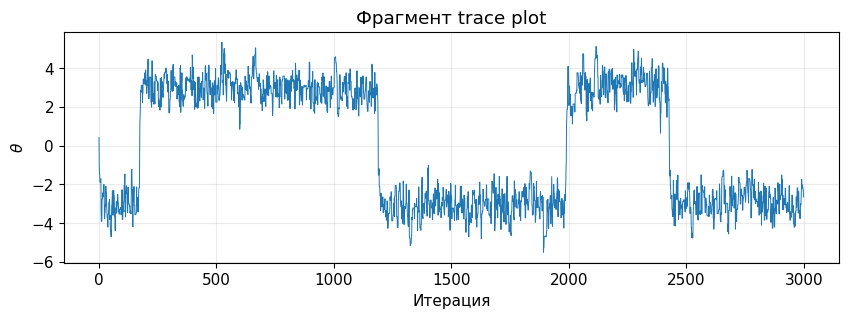

In [11]:
z = np.linspace(-6, 6, 600)
target = np.exp([log_target(v) for v in z])
fig, ax = plt.subplots()
ax.hist(mh_chain[1000:], bins=70, density=True, alpha=0.45, label="MCMC после burn-in")
ax.plot(z, target, lw=2.5, label="Целевая плотность")
ax.set(xlabel=r"$\theta$", ylabel="Плотность",
       title="Metropolis–Hastings: выборка и целевое распределение")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mh_chain[:3000], lw=0.7)
ax.set(xlabel="Итерация", ylabel=r"$\theta$", title="Фрагмент trace plot")
plt.show()

Trace plot показывает, как цепь перемещается во времени. Гистограмма похожа на целевую плотность — хороший знак, но не доказательство сходимости. Для надёжного анализа обычно запускают несколько цепей из разных начальных точек, проверяют trace plots, эффективный размер выборки (ESS), $\hat R$, автокорреляции и чувствительность к настройкам.

Слишком маленький шаг даёт высокую долю принятия, но медленное перемещение. Слишком большой шаг — много отказов. Одна лишь acceptance rate не является критерием качества.

### 7.2 Gibbs sampling: обновляем координаты по очереди

Gibbs sampling — частный случай MCMC, где каждую координату можно напрямую сэмплировать из её условного распределения при фиксированных остальных координатах.

Возьмём двумерное нормальное распределение с корреляцией $\rho$:
$$
(X\mid Y=y)\sim N(\rho y,1-\rho^2),\qquad
(Y\mid X=x)\sim N(\rho x,1-\rho^2).
$$
Чередуя эти два шага, получаем цепь с нужным совместным распределением.

In [12]:
def gibbs_bivariate_normal(n_steps=12_000, rho=0.85, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    out = np.zeros((n_steps, 2))
    x, y = 0.0, 0.0
    cond_sd = np.sqrt(1-rho**2)
    for t in range(n_steps):
        x = rng.normal(rho*y, cond_sd)
        y = rng.normal(rho*x, cond_sd)
        out[t] = [x, y]
    return out

gibbs = gibbs_bivariate_normal(rng=rng)

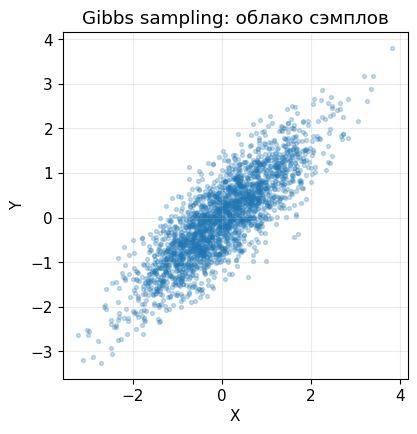

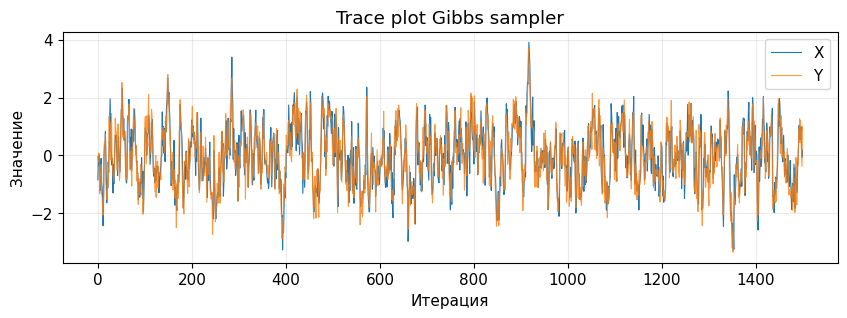

In [13]:
fig, ax = plt.subplots()
ax.scatter(gibbs[500::5, 0], gibbs[500::5, 1], s=8, alpha=0.25)
ax.set(xlabel="X", ylabel="Y", title="Gibbs sampling: облако сэмплов")
ax.set_aspect("equal", adjustable="box")
plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(gibbs[:1500, 0], label="X", lw=0.8)
ax.plot(gibbs[:1500, 1], label="Y", lw=0.8, alpha=0.8)
ax.set(xlabel="Итерация", ylabel="Значение", title="Trace plot Gibbs sampler")
ax.legend()
plt.show()

Gibbs особенно удобен, когда условные распределения известны и из них легко сэмплировать. В сложных моделях это часто не так. Metropolis–Hastings более универсален, но требует выбора proposal. Существуют и более продвинутые методы, например Hamiltonian Monte Carlo (HMC) и NUTS, которые используют градиенты и обычно эффективнее в непрерывных многомерных задачах.

## 8. Как считать статистики по MCMC-сэмплам

После диагностики цепи и удаления разумного warm-up можно считать характеристики по оставшимся сэмплам. Это численные приближения интегралов:
$$
\mathbb E[g(\theta)\mid D]\approx\frac1S\sum_{s=1}^S g(\theta^{(s)}).
$$
Например, posterior mean — среднее сэмплов, а credible interval — эмпирические квантили. Не забывайте: зависимость сэмплов означает, что $S$ итераций не эквивалентны $S$ независимым наблюдениям.

In [14]:
post_mcmc = mh_chain[5_000:]
print("Среднее:", np.mean(post_mcmc))
print("Медиана:", np.median(post_mcmc))
print("95% equal-tailed:", np.quantile(post_mcmc, [0.025, 0.975]))
print("Доля в правой моде (theta > 0):", np.mean(post_mcmc > 0))

Среднее: 0.7035509104910608
Медиана: 2.3727420549419644
95% equal-tailed: [-4.05658302  4.25695215]
Доля в правой моде (theta > 0): 0.61692


## 9. Принцип Бернштейна—фон Мизеса: prior всё меньше влияет при росте данных

В регулярных, достаточно хорошо специфицированных моделях при выполнении технических условий posterior при большом объёме данных часто становится приблизительно нормальным около оценки максимального правдоподобия, а влияние широкого фиксированного prior ослабевает.

Интуитивно: likelihood с ростом числа наблюдений становится всё более концентрированной. Если prior не исключает истинное значение и достаточно гладок около него, то данные начинают доминировать.

Это не универсальная гарантия. Результат может не работать в нерегулярных, неидентифицируемых, высокоразмерных или неверно специфицированных моделях; также важны условия на prior и асимптотический режим.

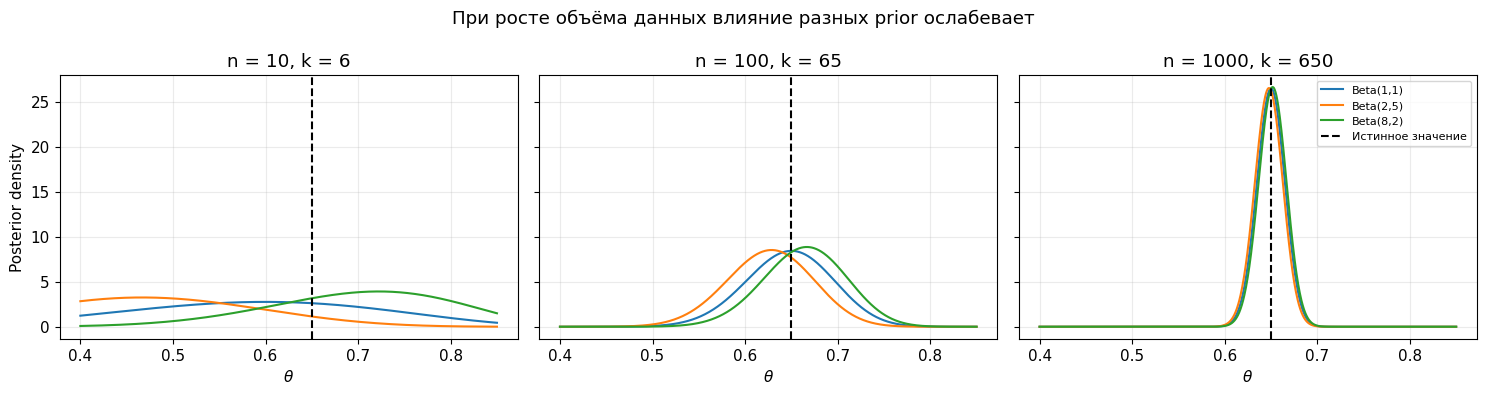

In [15]:
# Одна и та же истинная вероятность, разные prior.
# С ростом n posterior распределения концентрируются и становятся ближе друг к другу.
theta_true = 0.65
prior_specs = [(1, 1, "Beta(1,1)"),
               (2, 5, "Beta(2,5)"),
               (8, 2, "Beta(8,2)")]
ns = [10, 100, 1000]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n_now in zip(axes, ns):
    k_now = int(round(theta_true*n_now))
    xx = np.linspace(0.4, 0.85, 1000)
    for a0, b0, label in prior_specs:
        ax.plot(xx, beta.pdf(xx, a0+k_now, b0+n_now-k_now), label=label)
    ax.axvline(theta_true, color="black", ls="--", label="Истинное значение")
    ax.set_title(f"n = {n_now}, k = {k_now}")
    ax.set_xlabel(r"$\theta$")
axes[0].set_ylabel("Posterior density")
axes[-1].legend(fontsize=8)
fig.suptitle("При росте объёма данных влияние разных prior ослабевает")
plt.tight_layout()
plt.show()

В этом эксперименте данные сгенерированы не случайно: число успехов выбрано как ближайшее целое к $0.65n$, чтобы изолировать эффект роста $n$. В реальном эксперименте доля успехов случайна и колеблется вокруг истинного значения.

Для Beta–Binomial при фиксированных положительных параметрах prior это наглядная иллюстрация асимптотической идеи. Но не следует превращать её в лозунг «при большом n prior никогда не важен»: если prior исключает область истинного параметра, зависит от размера выборки или модель нарушает условия теоремы, вывод может быть другим.

## 10. Posterior predictive: что модель говорит о новых данных?

Параметрический интервал и предсказательный интервал отвечают на разные вопросы. Posterior по $\theta$ описывает неопределённость вероятности успеха. Чтобы предсказать число кликов в следующих $m$ показах, нужно:
1. взять $\theta$ из posterior;
2. сгенерировать новые данные при этом $\theta$;
3. повторить много раз.

Для Beta–Binomial posterior predictive имеет бета-биномиальное распределение; ниже используем прямую симуляцию.

Среднее число будущих кликов: 12.85955
95% predictive interval: [ 6. 18.]


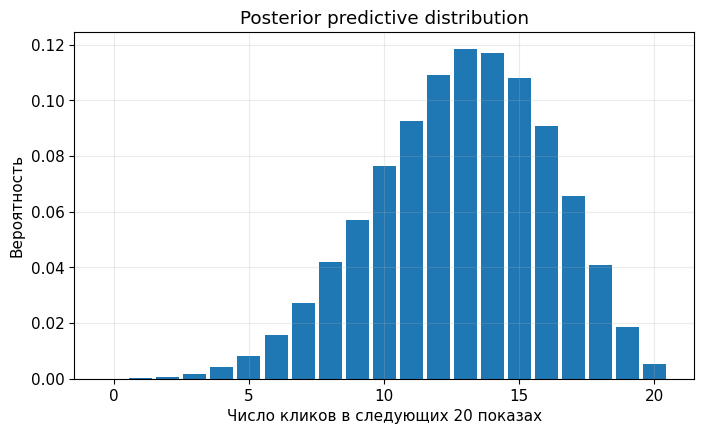

In [16]:
m_future = 20
theta_draws = post.rvs(size=100_000, random_state=rng)
future_clicks = rng.binomial(m_future, theta_draws)

print("Среднее число будущих кликов:", future_clicks.mean())
print("95% predictive interval:", np.quantile(future_clicks, [0.025, 0.975]))

fig, ax = plt.subplots()
ax.hist(future_clicks, bins=np.arange(-0.5, m_future+1.5, 1), density=True, rwidth=0.85)
ax.set(xlabel="Число кликов в следующих 20 показах", ylabel="Вероятность",
       title="Posterior predictive distribution")
plt.show()